# NIST SP 800-63B-4 RAG: Baseline vs. Cross-Encoder Re-Ranking

This notebook compares two workflows over the **same 307 chunks** from one official PDF:

1. Bi-encoder retrieval: dense Top 10, with the first 3 sent to the generator.
2. Advanced retrieval: cross-encode those same 10 candidates and send the re-ranked Top 3.

The notebook records the PDF checksum, rank shifts, paired answers, and warmed CPU latency; these outputs are experimental evidence, not submission prose.

## Environment

Run from the `rag-assignment` directory. Uncomment the installation command in a fresh environment. The default `recorded` backend displays verified local outputs. Select `local` to regenerate them on CPU, or `gemini` / `openai` after setting the matching API key.

In [1]:
# %pip install -q pypdf sentence-transformers transformers torch pandas numpy matplotlib requests google-genai openai python-dotenv

from pathlib import Path
import json, os, statistics, sys, time
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
load_dotenv(ROOT / ".env", override=False)
sys.path.insert(0, str(ROOT))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HOME", str(ROOT / ".cache" / "huggingface"))

GENERATOR_BACKEND = os.getenv("GENERATOR_BACKEND", "recorded")  # recorded | local | gemini | openai
os.environ.setdefault("LOCAL_LLM_NAME", "Qwen/Qwen2.5-0.5B-Instruct")
LATENCY_REPEATS = 5

## 1. Corpus preparation

The helper functions below are ordinary Python code included in this repository. They download/check the official PDF, normalize extracted text, form 180-word windows with 40-word overlap, and preserve page metadata. Both pipelines receive exactly the same chunks.

In [2]:
from run_retrieval_experiment import (
    BI_ENCODER_NAME, CROSS_ENCODER_NAME, EXPECTED_SHA256, PDF_PATH,
    CHUNK_WORDS, CHUNK_OVERLAP, chunk_pages, extract_pages, sha256,
    dense_top_k, rerank,
)

assert PDF_PATH.exists(), "Run the download/setup step in README.md first."
assert sha256(PDF_PATH) == EXPECTED_SHA256
pages = extract_pages(PDF_PATH)
chunks = chunk_pages(pages, CHUNK_WORDS, CHUNK_OVERLAP)
print({
    "pdf": PDF_PATH.name,
    "sha256": EXPECTED_SHA256,
    "pages": len(pages),
    "chunks": len(chunks),
    "chunk_words": CHUNK_WORDS,
    "overlap_words": CHUNK_OVERLAP,
})
pd.DataFrame([vars(chunk) for chunk in chunks]).head(3)

/local/mnt/workspace/lma/individual-project-AnilResearch0891/rag-assignment/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'pdf': 'NIST.SP.800-63B-4.pdf', 'sha256': 'd9ab89576b5ae2cfb3ba37781110788dea27a85a5079496dbfc1a79834670afd', 'pages': 129, 'chunks': 307, 'chunk_words': 180, 'overlap_words': 40}


,chunk_id,page_start,page_end,text
0,C0000,1,3,NIST Special Publication NIST SP 800-63B-4 Dig...
1,C0001,2,3,"Acting NIST Director Certain equipment, instru..."
2,C0002,3,3,are encouraged to review all draft publication...


## 2. Bi-encoder index and cross-encoder

The bi-encoder embeds queries and chunks independently. Normalized vectors allow cosine similarity through a dot product. The cross-encoder processes each `(query, chunk)` pair jointly, but only for the dense Top 10.

In [3]:
from sentence_transformers import CrossEncoder, SentenceTransformer

bi_encoder = SentenceTransformer(BI_ENCODER_NAME, device="cpu")
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME, device="cpu")

started = time.perf_counter()
corpus_embeddings = bi_encoder.encode(
    [chunk.text for chunk in chunks], batch_size=32,
    normalize_embeddings=True, convert_to_numpy=True,
    show_progress_bar=True,
)
index_seconds = time.perf_counter() - started
print(f"One-time corpus embedding: {index_seconds:.2f} seconds")


Batches:   0%|          | 0/10 [00:00<?, ?it/s]


Batches:  10%|█         | 1/10 [00:02<00:26,  3.00s/it]


Batches:  20%|██        | 2/10 [00:05<00:21,  2.70s/it]


Batches:  30%|███       | 3/10 [00:07<00:17,  2.47s/it]


Batches:  40%|████      | 4/10 [00:08<00:10,  1.79s/it]

...


Batches:  80%|████████  | 8/10 [00:11<00:02,  1.01s/it]


Batches:  90%|█████████ | 9/10 [00:12<00:00,  1.09it/s]


Batches: 100%|██████████| 10/10 [00:13<00:00,  1.17it/s]


Batches: 100%|██████████| 10/10 [00:13<00:00,  1.32s/it]

One-time corpus embedding: 13.26 seconds


## 3. Stress-test queries

Each selected answer-bearing chunk initially lies at dense rank 4-10 and must move into the re-ranked Top 3. This directly tests the assignment's failure condition.

In [4]:
CASES = [
    {
        "case": "F1",
        "mode": "Keyword trap / specific rule",
        "query": "What is the failed-try limit for the local PIN that unlocks a multifactor authenticator?",
        "gold_phrase": "no more than 10",
        "reference": "No more than 10 consecutive failed activation attempts.",
    },
    {
        "case": "F2",
        "mode": "Negation and modality constraint",
        "query": "Which biometric comparison method is explicitly forbidden even though face, iris, and fingerprints are discussed?",
        "gold_phrase": "Biometric comparison based on voice SHALL NOT be used",
        "reference": "Voice-based biometric comparison is prohibited.",
    },
]

In [5]:
runs, candidate_rows = [], []
for case in CASES:
    dense_i, dense_s, _ = dense_top_k(
        case["query"], bi_encoder, corpus_embeddings, top_k=10
    )
    rerank_i, cross_s, _ = rerank(
        case["query"], dense_i, chunks, cross_encoder
    )
    dense_rank = {int(i): r for r, i in enumerate(dense_i, 1)}
    rerank_rank = {int(i): r for r, i in enumerate(rerank_i, 1)}
    gold = [i for i, c in enumerate(chunks)
            if case["gold_phrase"].lower() in c.text.lower() and i in dense_rank]
    assert gold, f"Gold evidence for {case['case']} was not in dense Top 10"
    gold_i = min(gold, key=lambda i: rerank_rank[i])
    assert dense_rank[gold_i] > 3 and rerank_rank[gold_i] <= 3

    runs.append({**case, "dense_i": dense_i, "rerank_i": rerank_i,
                 "gold_i": gold_i, "dense_rank": dense_rank[gold_i],
                 "reranked_rank": rerank_rank[gold_i]})
    for i in dense_i:
        i = int(i)
        candidate_rows.append({
            "case": case["case"], "chunk": chunks[i].chunk_id,
            "pages": f"{chunks[i].page_start}-{chunks[i].page_end}",
            "dense_rank": dense_rank[i], "reranked_rank": rerank_rank[i],
            "gold": i == gold_i, "preview": chunks[i].text[:160],
        })

rank_shifts = pd.DataFrame([{
    "case": r["case"], "failure_mode": r["mode"],
    "gold_chunk": chunks[r["gold_i"]].chunk_id,
    "pages": f"{chunks[r['gold_i']].page_start}-{chunks[r['gold_i']].page_end}",
    "dense_rank": r["dense_rank"], "reranked_rank": r["reranked_rank"],
} for r in runs])
rank_shifts

,case,failure_mode,gold_chunk,pages,dense_rank,reranked_rank
0,F1,Keyword trap / specific rule,C0129,49-49,7,1
1,F2,Negation and modality constraint,C0113,43-44,4,1


In [6]:
pd.set_option("display.max_colwidth", 90)
pd.DataFrame(candidate_rows).sort_values(["case", "dense_rank"])

,case,chunk,pages,dense_rank,reranked_rank,gold,preview
0,F1,C0249,100-100,1,4,False,before throttling restrictions take effect. An excessively large blocklist will likely...
1,F1,C0090,35-36,2,2,False,"of the OTP . The verifier SHOULD implement or, if the authenticator output is less tha..."
2,F1,C0106,41-41,3,3,False,Sec. 5.1.1. 3.2.2. Rate Limiting (Throttling) When required by the authenticator type ...
3,F1,C0091,36-36,4,7,False,multi-factor OTP authenticator is “something you have” activated by either “something ...
4,F1,C0099,38-39,5,9,False,in length and SHALL either be unique over the authenticator’s lifetime or statisticall...
5,F1,C0013,7-8,6,10,False,. . . . 23 3.1.5. Multi-Factor OTPs . . . . . . . . . . . . . . . . . . . . . . . . . ...
6,F1,C0129,49-49,7,1,True,"to a stored authentication key. In all cases, the activation secret SHALL remain withi..."
7,F1,C0130,49-50,8,5,False,"output to the central verifier, the verifier MAY implement this retry-limiting mechani..."
8,F1,C0102,39-40,9,6,False,"are identical to those for a single-factor cryptographic verifier, as described in Sec..."
9,F1,C0045,17-18,10,8,False,two separate authentication factors. A multi-factor authenticator requires two factors...


## 4. Identical prompting and paired answers

Only the selected Top 3 chunks change. The recorded run used `Qwen/Qwen2.5-0.5B-Instruct` locally. It demonstrates one successful answer repair and one important limitation: reranking can restore evidence while a weak generator still fails to use it.

In [7]:
from run_final_experiment import LOCAL_LLM_NAME, generate_answer, make_prompt

RECORDED_LOCAL_ANSWERS = {
    "F1": {
        "answer1": "The failed-try limit for the local PIN that unlocks a multifactor authenticator is 64 bits.",
        "answer2": "The failed-try limit for the local PIN that unlocks a multifactor authenticator is 10.",
    },
    "F2": {
        "answer1": "Biometric comparison methods are explicitly forbidden despite face, iris, and fingerprints being discussed.",
        "answer2": "Face, iris, and fingerprints are discussed, but facial images cannot be taken directly.",
    },
}

if GENERATOR_BACKEND == "local":
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained(LOCAL_LLM_NAME)
    model = AutoModelForCausalLM.from_pretrained(LOCAL_LLM_NAME)
    answers = {}
    for run in runs:
        a1, _ = generate_answer(
            make_prompt(run["query"], [chunks[int(i)] for i in run["dense_i"][:3]]),
            tokenizer, model,
        )
        a2, _ = generate_answer(
            make_prompt(run["query"], [chunks[int(i)] for i in run["rerank_i"][:3]]),
            tokenizer, model,
        )
        answers[run["case"]] = {"answer1": a1, "answer2": a2}
elif GENERATOR_BACKEND == "gemini":
    from google import genai
    if not os.getenv("GEMINI_API_KEY"):
        raise RuntimeError("Set GEMINI_API_KEY before using the Gemini backend")
    client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    answers = {}
    for run in runs:
        prompt1 = make_prompt(run["query"], [chunks[int(i)] for i in run["dense_i"][:3]])
        prompt2 = make_prompt(run["query"], [chunks[int(i)] for i in run["rerank_i"][:3]])
        a1 = client.models.generate_content(model="gemini-3.8-flash", contents=prompt1).text.strip()
        a2 = client.models.generate_content(model="gemini-3.8-flash", contents=prompt2).text.strip()
        answers[run["case"]] = {"answer1": a1, "answer2": a2}
elif GENERATOR_BACKEND == "openai":
    from openai import OpenAI
    if not os.getenv("OPENAI_API_KEY"):
        raise RuntimeError("Set OPENAI_API_KEY before using the OpenAI backend")
    client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])
    model_name = os.getenv("OPENAI_MODEL", "gpt-6-luna")
    answers = {}
    for run in runs:
        prompt1 = make_prompt(run["query"], [chunks[int(i)] for i in run["dense_i"][:3]])
        prompt2 = make_prompt(run["query"], [chunks[int(i)] for i in run["rerank_i"][:3]])
        a1 = client.responses.create(model=model_name, input=prompt1).output_text.strip()
        a2 = client.responses.create(model=model_name, input=prompt2).output_text.strip()
        answers[run["case"]] = {"answer1": a1, "answer2": a2}
else:
    answers = RECORDED_LOCAL_ANSWERS

answer_table = pd.DataFrame([{
    "case": r["case"], "reference": r["reference"],
    "answer1_baseline": answers[r["case"]]["answer1"],
    "answer2_reranked": answers[r["case"]]["answer2"],
} for r in runs])
answer_table

,case,reference,answer1_baseline,answer2_reranked
0,F1,No more than 10 consecutive failed activation attempts.,The failed-try limit for the local PIN that unlocks a multifactor authenticator is 64 ...,The failed-try limit for the local PIN that unlocks a multifactor authenticator is 10.
1,F2,Voice-based biometric comparison is prohibited.,"Biometric comparison methods are explicitly forbidden despite face, iris, and fingerpr...","Face, iris, and fingerprints are discussed, but facial images cannot be taken directly."


### Candid interpretation

- **F1:** Answer 1 confused a bit-length passage with an attempt count. After chunk C0129 moved from rank 7 to rank 1, Answer 2 correctly returned 10.
- **F2:** Chunk C0113 moved from rank 4 to rank 1, so retrieval relevance was restored. The 0.5B generator still failed to state that voice comparison is prohibited. This is a generator-following failure and must not be reported as an end-to-end answer success. Re-run with a stronger API model if available.

## 5. Latency profiling

In [8]:
# Excludes model loading, PDF extraction, one-time indexing, and generator latency.
latency_rows = []
for case in CASES:
    # Warm up each query shape before collecting its repeated measurements.
    warm_i, _, _ = dense_top_k(case["query"], bi_encoder, corpus_embeddings)
    rerank(case["query"], warm_i, chunks, cross_encoder)
    baseline, reranking, advanced = [], [], []
    for _ in range(LATENCY_REPEATS):
        dense_i, _, dense_ms = dense_top_k(case["query"], bi_encoder, corpus_embeddings)
        _, _, rerank_ms = rerank(case["query"], dense_i, chunks, cross_encoder)
        baseline.append(dense_ms)
        reranking.append(rerank_ms)
        advanced.append(dense_ms + rerank_ms)
    latency_rows.append({
        "case": case["case"],
        "baseline_retrieval_ms": statistics.median(baseline),
        "reranking_only_ms": statistics.median(reranking),
        "advanced_total_ms": statistics.median(advanced),
    })
latency_table = pd.DataFrame(latency_rows)
latency_table

,case,baseline_retrieval_ms,reranking_only_ms,advanced_total_ms
0,F1,22.440337,682.438651,703.031491
1,F2,11.521524,175.554346,198.261848


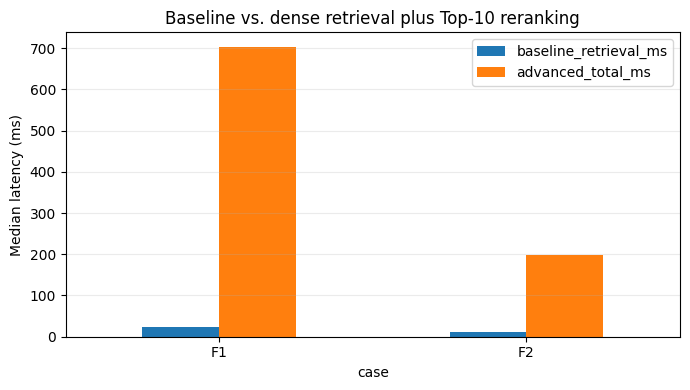

In [9]:
ax = latency_table.set_index("case")[["baseline_retrieval_ms", "advanced_total_ms"]].plot(
    kind="bar", figsize=(7, 4), rot=0
)
ax.set_ylabel("Median latency (ms)")
ax.set_title("Baseline vs. dense retrieval plus Top-10 reranking")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Architecture comparison and scaling

- **Bi-encoder:** query and chunk are embedded independently. Chunk embeddings are reusable, making vector search fast, but there is no direct token-level interaction between query and passage.
- **Cross-encoder:** query and passage are processed jointly with self-attention. It can better resolve negation and fine-grained constraints, but it performs a separate model forward pass for every pair.
- **Why not cross-encode everything?** For `N` chunks, whole-corpus cross-encoding requires `N` expensive forward passes for every query and cannot reuse precomputed chunk scores. Here dense retrieval reduces 307 chunks to 10 before reranking; the same saving is essential at larger scale.

## 7. Export evidence for the student-written report

In [10]:
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
rank_shifts.to_csv(OUTPUT_DIR / "notebook_rank_shifts.csv", index=False)
answer_table.to_csv(OUTPUT_DIR / "notebook_answers.csv", index=False)
latency_table.to_csv(OUTPUT_DIR / "notebook_latency.csv", index=False)
metadata = {
    "pdf_sha256": EXPECTED_SHA256, "pages": len(pages), "chunks": len(chunks),
    "chunk_words": CHUNK_WORDS, "chunk_overlap": CHUNK_OVERLAP,
    "bi_encoder": BI_ENCODER_NAME, "cross_encoder": CROSS_ENCODER_NAME,
    "generator_backend": GENERATOR_BACKEND,
    "local_generator": LOCAL_LLM_NAME,
    "gemini_model": os.getenv("GEMINI_MODEL", "gemini-3.8-flash"),
    "openai_model": os.getenv("OPENAI_MODEL", "gpt-6-luna"),
    "index_seconds": index_seconds,
}
(OUTPUT_DIR / "notebook_metadata.json").write_text(json.dumps(metadata, indent=2))
metadata

{'pdf_sha256': 'd9ab89576b5ae2cfb3ba37781110788dea27a85a5079496dbfc1a79834670afd',
 'pages': 129,
 'chunks': 307,
 'chunk_words': 180,
 'chunk_overlap': 40,
 'bi_encoder': 'sentence-transformers/all-MiniLM-L6-v2',
 'cross_encoder': 'cross-encoder/ms-marco-MiniLM-L-6-v2',
 'generator_backend': 'recorded',
 'local_generator': 'Qwen/Qwen2.5-0.5B-Instruct',
 'index_seconds': 13.262024316936731}